In [1]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("kaggle-pulse-vision")

In [2]:
!git clone -b main --single-branch --depth 1 https://{secret_value_0}@github.com/mmmishaa/pulse-vision.git

Cloning into 'pulse-vision'...
remote: Enumerating objects: 33, done.
remote: Counting objects: 100% (33/33), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 33 (delta 0), reused 21 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (33/33), 12.08 KiB | 12.08 MiB/s, done.


In [3]:
import sys
sys.path.append("/kaggle/working/pulse-vision")

In [4]:
from src.data.dataset import RPPGDataset, data_split
from src.models.model import EfficientPhys_C
from src.models.metrics import mae, rmse, bpm_pearson_corr
from src.dsp.dsp_processor import estimate_bpm_from_wave, estimate_bpm_from_diff_wave
from src.dsp.dsp_processor import apply_filter

import torch
from torch.utils.data import DataLoader
from pathlib import Path
import torchvision.transforms.v2 as v2
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np
import pandas as pd

In [5]:
MCD_DIR = Path("/kaggle/input/datasets/mishasavinov/mcd-rppg-dataset")

metadata_path = MCD_DIR / "metadata.csv"
val_df_patients, _ = data_split(metadata_path=metadata_path)

device = "cuda"

model1_weights_path = "/kaggle/input/models/mishasavinov/efficientphys-c/pytorch/default/1/efficientphys_c_v1.pt"
model2_weights_path = "/kaggle/input/models/mishasavinov/efficientphys-c/pytorch/default/1/efficientphys_c_v2.pt"

In [6]:
model1 = EfficientPhys_C(n_frames=100).to(device)
model1.load_state_dict(torch.load(model1_weights_path, weights_only=True, map_location=device))

model2 = EfficientPhys_C(n_frames=100).to(device)
model2.load_state_dict(torch.load(model2_weights_path, weights_only=True, map_location=device))

model1.eval()
model2.eval()

EfficientPhys_C(
  (batchnorm): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (block1): Sequential(
    (0): TemporalShiftModule()
    (1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): Tanh()
    (3): TemporalShiftModule()
    (4): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): Tanh()
    (6): AttentionMask(
      (conv): Conv2d(32, 1, kernel_size=(1, 1), stride=(1, 1))
      (sigmoid): Sigmoid()
    )
  )
  (downsample_block1): Sequential(
    (0): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (1): Dropout(p=0.25, inplace=False)
  )
  (block2): Sequential(
    (0): TemporalShiftModule()
    (1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): Tanh()
    (3): TemporalShiftModule()
    (4): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): Tanh()
    (6): AttentionMask(
      (conv): Conv2d(64, 1, kernel_size=(1, 1), stride=(1, 1))
      (si

In [7]:
transform = v2.Compose([v2.ToDtype(torch.float32, scale=True)])

preds_m1, preds_m2, ground_truths = [], [], []
saved_waves = {}

clip_len = 100
batch_size = 256

with torch.no_grad():
    for row in tqdm(val_df_patients.itertuples(), total=len(val_df_patients), desc="Evaluation"):
        frames_path = MCD_DIR / row.frames_file
        raw_frames = np.load(frames_path, mmap_mode="r")
        num_frames = int(row.num_frames)

        clips = []
        for start in range(0, num_frames - clip_len + 1, clip_len):
            clip = np.array(raw_frames[start : start + clip_len])
            clip = torch.from_numpy(clip).permute(0, 3, 1, 2)
            clip = transform(clip)
            clips.append(clip)

        if len(clips) == 0:
            continue

        video_preds1, video_preds2 = [], []
        for b_idx in range(0, len(clips), batch_size):
            batch = torch.stack(clips[b_idx : b_idx + batch_size]).to(device)
            with torch.amp.autocast("cuda", enabled=("cuda" in device)):
                out1 = model1(batch)
                out2 = model2(batch)
            video_preds1.append(out1.cpu().numpy().flatten())
            video_preds2.append(out2.cpu().numpy().flatten())

        full_signal_m1 = np.concatenate(video_preds1)
        full_signal_m2 = np.concatenate(video_preds2)

        bpm_1 = estimate_bpm_from_wave(wave=full_signal_m1, fps=30.0)
        bpm_2 = estimate_bpm_from_diff_wave(diff_wave=full_signal_m2, fps=30.0)
        true_bpm = float(row.pulse)

        preds_m1.append(bpm_1)
        preds_m2.append(bpm_2)
        ground_truths.append(true_bpm)

        if len(saved_waves) < 5:
            saved_waves[f"{row.patient_id} ({row.step})"] = {
                "m1": full_signal_m1,
                "m2": full_signal_m2,
                "gt": np.load(MCD_DIR / row.ppg_file)[:len(full_signal_m1)],
                "true_bpm": true_bpm,
                "bpm1": bpm_1,
                "bpm2": bpm_2
            }

preds_m1 = np.array(preds_m1)
preds_m2 = np.array(preds_m2)
ground_truths = np.array(ground_truths)

metrics_summary = pd.DataFrame({
    "Metric": ["MAE (BPM)", "RMSE (BPM)", "Pearson r"],
    "Model 1 (Raw PPG)": [
        mae(preds_m1, ground_truths),
        rmse(preds_m1, ground_truths),
        bpm_pearson_corr(preds_m1, ground_truths)
    ],
    "Model 2 (Diff PPG)": [
        mae(preds_m2, ground_truths),
        rmse(preds_m2, ground_truths),
        bpm_pearson_corr(preds_m2, ground_truths)
    ]
})

print("\nModel Comparison Results:")
print(metrics_summary.to_string(index=False))

Evaluation: 100%|██████████| 240/240 [05:37<00:00,  1.41s/it]


Model Comparison Results:
    Metric  Model 1 (Raw PPG)  Model 2 (Diff PPG)
 MAE (BPM)          11.943294           11.683171
RMSE (BPM)          16.706783           16.311717
 Pearson r           0.622207            0.688114


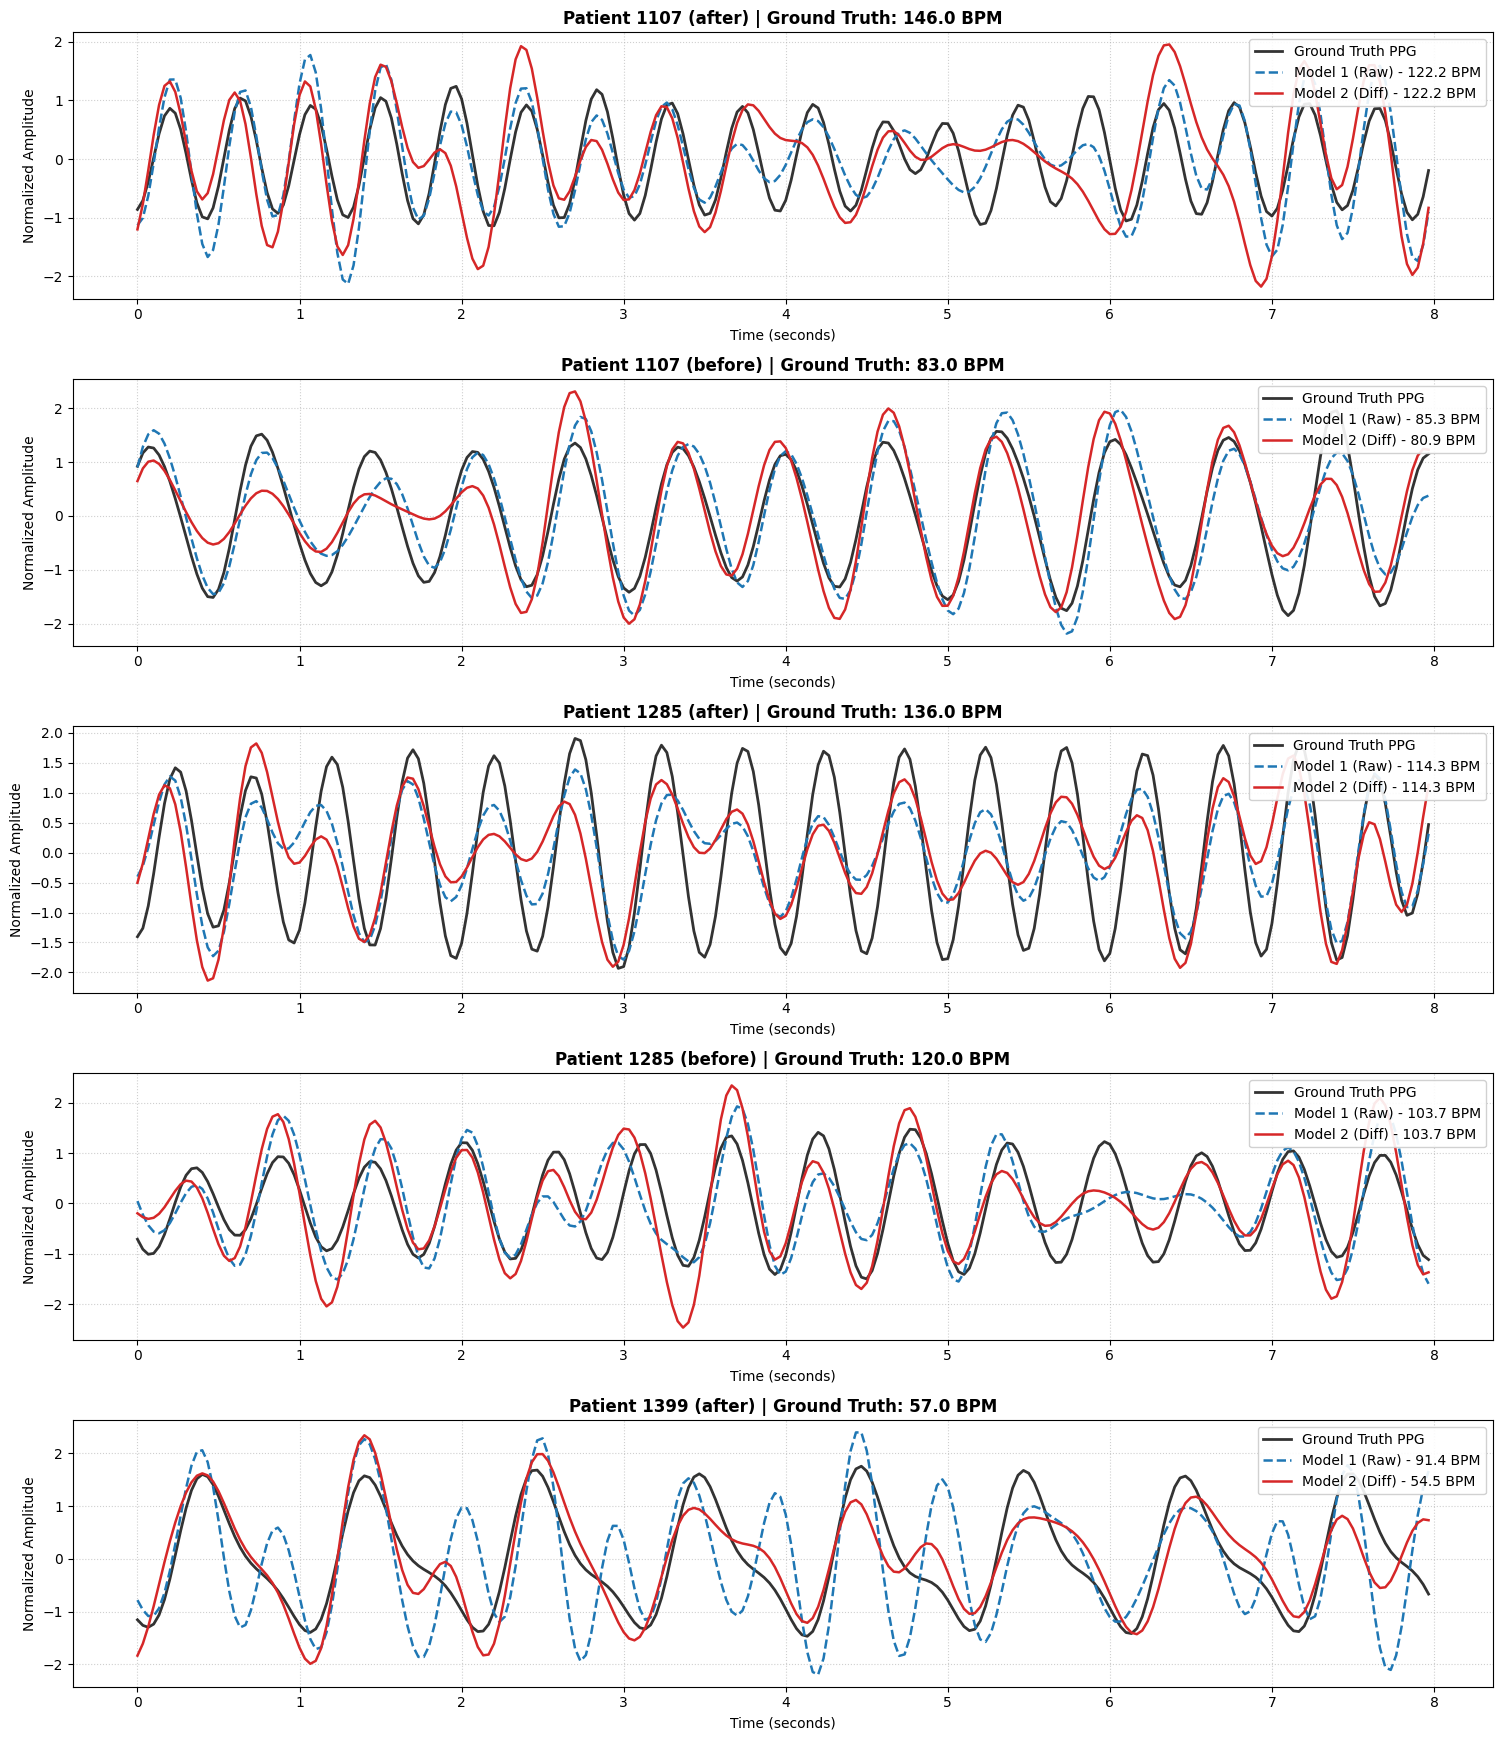

In [8]:
filter_cutoff_frequencies = [0.75, 2.5]
FPS = 30.0
window_sec = 8.0
window_frames = int(window_sec * FPS)

fig, axes = plt.subplots(nrows=len(saved_waves), ncols=1, figsize=(15, 3.5 * len(saved_waves)), sharex=False)
if len(saved_waves) == 1:
    axes = [axes]

for ax, (patient_label, data) in zip(axes, saved_waves.items()):
    m2_centered = data["m2"] - np.mean(data["m2"])
    wave_m2 = np.cumsum(m2_centered, dtype=np.float64)

    wave_gt_filt = apply_filter(data["gt"], fps=FPS, filter_cutoff_frequencies=filter_cutoff_frequencies)
    wave_m1_filt = apply_filter(data["m1"], fps=FPS, filter_cutoff_frequencies=filter_cutoff_frequencies)
    wave_m2_filt = apply_filter(wave_m2, fps=FPS, filter_cutoff_frequencies=filter_cutoff_frequencies)

    wave_gt_norm = (wave_gt_filt - wave_gt_filt.mean()) / (wave_gt_filt.std() + 1e-7)
    wave_m1_norm = (wave_m1_filt - wave_m1_filt.mean()) / (wave_m1_filt.std() + 1e-7)
    wave_m2_norm = (wave_m2_filt - wave_m2_filt.mean()) / (wave_m2_filt.std() + 1e-7)

    start_idx = 100
    end_idx = start_idx + window_frames
    time_axis = np.arange(window_frames) / FPS

    ax.plot(time_axis, wave_gt_norm[start_idx:end_idx], label="Ground Truth PPG", color="black", linewidth=2.0, alpha=0.8)
    ax.plot(time_axis, wave_m1_norm[start_idx:end_idx], label=f"Model 1 (Raw) - {data['bpm1']:.1f} BPM", color="#1f77b4", linestyle="--", linewidth=1.8)
    ax.plot(time_axis, wave_m2_norm[start_idx:end_idx], label=f"Model 2 (Diff) - {data['bpm2']:.1f} BPM", color="#d62728", linewidth=1.8)

    ax.set_title(f"Patient {patient_label} | Ground Truth: {data['true_bpm']:.1f} BPM", fontsize=12, fontweight="bold")
    ax.set_xlabel("Time (seconds)", fontsize=10)
    ax.set_ylabel("Normalized Amplitude", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.6)
    ax.legend(loc="upper right", framealpha=0.9)

plt.tight_layout()
plt.show()